# Data Extraction from Chembl part 1

In [ ]:
# Data Extraction from chembl

!pip install chembl_webresource_client
!pip install rdkit==2024.09.6

### **Description of the chembl id '' and uniprot id '' from chembl database**

In [2]:
# importing libraries
import pandas as pd
import numpy as np
from chembl_webresource_client.new_client import new_client
# Searching for Target Protein
# Target search for DPP4
target = new_client.target
target_query = target.search('DPP4')
targets = pd.DataFrame.from_dict(target_query)
targets



d:\ANACONDA\Lib\site-packages\chembl_webresource_client\__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
0,[],Sus scrofa,Dipeptidyl peptidase 4,10.0,False,CHEMBL3813,"[{'accession': 'P22411', 'component_descriptio...",SINGLE PROTEIN,9823
1,[],Mus musculus,Dipeptidyl peptidase 4,10.0,False,CHEMBL3883,"[{'accession': 'P28843', 'component_descriptio...",SINGLE PROTEIN,10090
2,[],Bos taurus,Dipeptidyl peptidase 4,9.0,False,CHEMBL2559,"[{'accession': 'P81425', 'component_descriptio...",SINGLE PROTEIN,9913
3,[],Homo sapiens,Dipeptidyl peptidase 4,9.0,False,CHEMBL284,"[{'accession': 'P27487', 'component_descriptio...",SINGLE PROTEIN,9606
4,[],Homo sapiens,Dipeptidyl peptidase II and dipeptidyl peptida...,9.0,False,CHEMBL2111469,"[{'accession': 'P27487', 'component_descriptio...",SELECTIVITY GROUP,9606
5,[],Rattus norvegicus,Dipeptidyl peptidase 4,8.0,False,CHEMBL4653,"[{'accession': 'P14740', 'component_descriptio...",SINGLE PROTEIN,10116


**Filter for Homo sapiens Single Protein** descrition of protein

In [3]:
selected_target = targets[(targets.organism == 'Homo sapiens') & (targets.target_type == 'SINGLE PROTEIN')].target_chembl_id.iloc[0]
selected_target

'CHEMBL284'

### ***Confirm the CHEMBL id from website also***

## Retrieval of DPP4 Bioactivity Data from ChEMBL

Bioactivity data were retrieved from the ChEMBL database using the ChEMBL REST API. The selected target was human dipeptidyl peptidase-4 (DPP4), identified by the ChEMBL target identifier **CHEMBL284**.

The retrieval was restricted to experimentally measured **IC50** values obtained from **binding assays**. The following criteria were applied:

* **Target:** CHEMBL284, corresponding to the selected DPP4 target.
* **Standard activity type:** IC50.
* **Activity relation:** `=`, retaining only exact IC50 measurements and excluding measurements reported as `<`, `>`, `<=`, or `>=`.
* **Assay type:** `B`, corresponding to binding assays.
* **Records per request:** 1000 records were requested per API call.

Because the ChEMBL REST API returns data in pages, pagination was implemented to retrieve all available records satisfying the specified criteria. The retrieval process continued until no additional records were available.

The retrieved activity records were subsequently converted into a pandas DataFrame for further inspection and preprocessing.

It should be noted that the retrieved dataset represents **activity measurements rather than unique compounds**. Therefore, the same compound may occur multiple times because it may have been evaluated in different assays or reported in different studies. Additional data-cleaning and standardization steps are required before constructing the final machine-learning dataset, including handling duplicate compounds, missing values, inconsistent units, and multiple measurements for the same compound.


In [4]:
import requests
import pandas as pd


# ============================================================================
# RETRIEVE RAW DPP4 BIOACTIVITY DATA FROM ChEMBL
# ============================================================================

# ChEMBL REST API endpoint for activity data
url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"


# Query parameters used to retrieve DPP4 IC50 binding-assay data
params = {
    "target_chembl_id": "CHEMBL284",
    "standard_type": "IC50",
    "relation": "=",
    "assay_type": "B",
    "limit": 1000,
    "offset": 0
}


# Empty list to store all retrieved activity records
all_activities = []


# Retrieve all available records using pagination
while True:

    response = requests.get(
        url,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    data = response.json()

    activities = data.get("activities", [])

    if not activities:
        break

    all_activities.extend(activities)

    if not data["page_meta"]["next"]:
        break

    params["offset"] += params["limit"]


# Convert all retrieved ChEMBL records into a DataFrame
df = pd.DataFrame(all_activities)


# ============================================================================
# SAVE RAW ChEMBL DATA
# ============================================================================

# Save the data exactly as retrieved from ChEMBL.
# No filtering, unit conversion, duplicate removal, or other preprocessing
# has been performed at this stage.
raw_file = "DPP4_IC50_ChEMBL_raw.csv"

df.to_csv(raw_file, index=False)


# ============================================================================
# DISPLAY RETRIEVAL SUMMARY
# ============================================================================

print("=" * 100)
print("RAW ChEMBL DPP4 BIOACTIVITY DATA")
print("=" * 100)

print(f"\nTotal activity records retrieved: {len(df)}")
print(f"DataFrame shape: {df.shape}")
print(f"Raw data saved as: {raw_file}")

print("\nFirst 3 records:")
display(df.head(3))

RAW ChEMBL DPP4 BIOACTIVITY DATA

Total activity records retrieved: 4879
DataFrame shape: (4879, 47)
Raw data saved as: DPP4_IC50_ChEMBL_raw.csv

First 3 records:


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,105501,[],CHEMBL666573,In vitro inhibition of human Dipeptidylpeptida...,B,None,None,BAO_0000190,...,Homo sapiens,Dipeptidyl peptidase 4,9606,None,None,IC50,uM,UO_0000065,None,217.0
1,None,None,106644,[],CHEMBL666573,In vitro inhibition of human Dipeptidylpeptida...,B,None,None,BAO_0000190,...,Homo sapiens,Dipeptidyl peptidase 4,9606,None,None,IC50,uM,UO_0000065,None,41.0
2,None,None,106647,[],CHEMBL666573,In vitro inhibition of human Dipeptidylpeptida...,B,None,None,BAO_0000190,...,Homo sapiens,Dipeptidyl peptidase 4,9606,None,None,IC50,uM,UO_0000065,None,15.0


### Selection of IC50 Values in nM

Filter the dataset to retain only activity records with IC50 values reported in nanomolar (nM), ensuring a consistent unit for subsequent analysis.

In [5]:
df['standard_units'].value_counts(dropna=False)

standard_units
nM         4859
ug.mL-1      20
Name: count, dtype: int64

In [6]:
df = df[df['standard_units'] == 'nM']

In [7]:
#Removing null rows
df.dropna(subset=['standard_value'], inplace=True)

In [8]:
# saving as a bioactivity data file
df.to_csv('bioactivity_data_raw.csv', index=False)

In [9]:
# change standard value data type into float 64
df["standard_value"] = df["standard_value"].astype(float)

Data Processing

In [10]:
# extracting onlyselection = ['molecule_chembl_id','canonical_smiles','standard_value']
selection = ['molecule_chembl_id','canonical_smiles','standard_value']
df1 = df[selection]
df1

,molecule_chembl_id,canonical_smiles,standard_value
0,CHEMBL93558,N[C@@H](CC1CCCCC1)C(=O)N1CCCCC1,217000.0
1,CHEMBL443622,C[C@H](N)C(=O)N1CCCC1,41000.0
2,CHEMBL403882,O=C([C@@H]1CCCN1)N1CCCC1,15000.0
3,CHEMBL328795,NC(=O)CC(N)C(=O)N1CCCC1,188000.0
4,CHEMBL97674,NCCCCC(N)C(=O)N1CCCCC1,247000.0
...,...,...,...
4874,CHEMBL6188802,Cc1cc(C[C@@H](N)Cn2nncc2-c2ccccc2)c(F)cc1F,340.0
4875,CHEMBL6190034,N[C@H](Cc1cc(F)c(F)cc1F)Cn1cc(-c2ccccc2)nn1,190.0
4876,CHEMBL6189534,COc1ccc(-c2cnnn2C[C@H](N)Cc2cc(C)c(F)cc2F)cc1,340.0
4877,CHEMBL6190892,N[C@H](Cc1cc(F)c(F)cc1F)Cn1cc(CO)nn1,190.0


In [35]:
# handling duplicate entrys by taking average 

df1 = df1.groupby("canonical_smiles", as_index=False).agg({
    "standard_value": "mean",
    **{col: "first" for col in df1.columns if col not in ["canonical_smiles", "standard_value"]}
})
df1

,canonical_smiles,standard_value,molecule_chembl_id
0,Br.Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)...,1.0,CHEMBL5596356
1,Br.Cc1ccc(=N)n(Cc2cccc(F)c2)c1,34650.0,CHEMBL3310988
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,28200.0,CHEMBL4246951
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,60.0,CHEMBL260701
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,16.0,CHEMBL3913618
...,...,...,...
3995,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,2810.0,CHEMBL3343900
3996,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1.[Cl-],1410.0,CHEMBL511367
3997,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,0.6,CHEMBL165
3998,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,10.0,CHEMBL3675619


In [36]:
# labelling compounds as either active or inactive or intermediate
# standard value less or equal than 100 is active and greater than 100 is inactive
bioactivity_class = []
for i in df1.standard_value:
    if float(i) <= 100:
        bioactivity_class.append("Active")
    elif float(i) > 100:
        bioactivity_class.append("Inactive")


In [37]:
#combine new bioactivity class with retrived data
bioactivity_class = pd.Series(bioactivity_class, name='bioactivity_class')
df2 = pd.concat([df1, bioactivity_class], axis=1)
df2

,canonical_smiles,standard_value,molecule_chembl_id,bioactivity_class
0,Br.Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)...,1.0,CHEMBL5596356,Active
1,Br.Cc1ccc(=N)n(Cc2cccc(F)c2)c1,34650.0,CHEMBL3310988,Inactive
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,28200.0,CHEMBL4246951,Inactive
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,60.0,CHEMBL260701,Active
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,16.0,CHEMBL3913618,Active
...,...,...,...,...
3995,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,2810.0,CHEMBL3343900,Inactive
3996,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1.[Cl-],1410.0,CHEMBL511367,Inactive
3997,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,0.6,CHEMBL165,Active
3998,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,10.0,CHEMBL3675619,Active


## **Convert IC50 to pIC50**
To allow **IC50** data to be more uniformly distributed, we will convert **IC50** to the negative logarithmic scale which is essentially **-log10(IC50)**.

This custom function pIC50() will accept a DataFrame as input and will:
* Take the IC50 values from the ``standard_value`` column and converts it from nM to M by multiplying the value by 10$^{-9}$
* Take the molar value and apply -log10
* Delete the ``standard_value`` column and create a new ``pIC50`` column


Initially we start this by normalizing Standard_value column by fixing values greater than 100,000,000 at 100,000,000 otherwise the negative logarithmic value will become negative.

In [38]:
#capping IC50 and then converting IC50 into pIC50 where pIC50 = -log(IC50*10 (to the power)-9)
def norm_value(input):
    norm = []

    for i in input['standard_value']:
        if i > 100000000:
          i = 100000000
        norm.append(i)

    input['standard_value_norm'] = norm
    x = input.drop('standard_value', axis=1)

    return x

In [39]:
df3 = norm_value(df2)
df3

,canonical_smiles,molecule_chembl_id,bioactivity_class,standard_value_norm
0,Br.Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)...,CHEMBL5596356,Active,1.0
1,Br.Cc1ccc(=N)n(Cc2cccc(F)c2)c1,CHEMBL3310988,Inactive,34650.0
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,CHEMBL4246951,Inactive,28200.0
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,CHEMBL260701,Active,60.0
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,CHEMBL3913618,Active,16.0
...,...,...,...,...
3995,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,CHEMBL3343900,Inactive,2810.0
3996,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1.[Cl-],CHEMBL511367,Inactive,1410.0
3997,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,CHEMBL165,Active,0.6
3998,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,CHEMBL3675619,Active,10.0


In [40]:
def pIC50(input):
    pIC50 = []

    for i in input['standard_value_norm']:
        molar = i*(10**-9) # Converts nM to M
        pIC50.append(-np.log10(molar))

    input['pIC50'] = pIC50
    x = input.drop('standard_value_norm', axis=1)

    return x

In [48]:
df_final = pIC50(df3)
df_final

,canonical_smiles,molecule_chembl_id,bioactivity_class,pIC50
0,Br.Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)...,CHEMBL5596356,Active,9.000000
1,Br.Cc1ccc(=N)n(Cc2cccc(F)c2)c1,CHEMBL3310988,Inactive,4.460297
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,CHEMBL4246951,Inactive,4.549751
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,CHEMBL260701,Active,7.221849
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,CHEMBL3913618,Active,7.795880
...,...,...,...,...
3995,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,CHEMBL3343900,Inactive,5.551294
3996,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1.[Cl-],CHEMBL511367,Inactive,5.850781
3997,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,CHEMBL165,Active,9.221849
3998,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,CHEMBL3675619,Active,8.000000


In [49]:
df_final.to_csv("DPP4_compounds.csv", index=False)

In [50]:
print(f"DataFrame shape: {df_final.shape}")

DataFrame shape: (4000, 4)


## ***Data Filtering part 2***

In [51]:
# importing necessary libraries
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, PandasTools

In [53]:
df= pd.read_csv('DPP4_compounds.csv')
df.head()
df.shape

(4000, 4)

 The code below extract the longest molecular fingerprint from canonical smiles and then replaces original with cleaned version

In [54]:
# removing unwanted salts or ions that are part of drug and not original compound
df_no_smiles = df.drop(columns='canonical_smiles')

In [55]:
smiles = []

for i in df.canonical_smiles.tolist():
  cpd = str(i).split('.')
  cpd_longest = max(cpd, key = len)
  smiles.append(cpd_longest)

smiles = pd.Series(smiles, name = 'canonical_smiles')

In [56]:
df_clean_smiles = pd.concat([df_no_smiles,smiles], axis=1)
df_clean_smiles

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...
...,...,...,...,...
3995,CHEMBL3343900,Inactive,5.551294,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1
3996,CHEMBL511367,Inactive,5.850781,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1
3997,CHEMBL165,Active,9.221849,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1
3998,CHEMBL3675619,Active,8.000000,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...


In [58]:
# applying Lipinski's rule of 5
# using RDKIT to evaluate molecule's drug-likeness
def calculate_ro5_properties(smiles):
    """
    Test if input molecule (SMILES) fulfills Lipinski's rule of five.

    Parameters
    ----------
    smiles : str
        SMILES for a molecule.

    Returns
    -------
    pandas.Series
        Molecular weight, number of hydrogen bond acceptors/donor and logP value
        and Lipinski's rule of five compliance for input molecule.
    """
    # RDKit molecule from SMILES
    molecule = Chem.MolFromSmiles(smiles)
    # Calculate Ro5-relevant chemical properties
    molecular_weight = Descriptors.ExactMolWt(molecule)
    n_hba = Descriptors.NumHAcceptors(molecule)
    n_hbd = Descriptors.NumHDonors(molecule)
    logp = Descriptors.MolLogP(molecule)
    # Check if Ro5 conditions fulfilled
    conditions = [molecular_weight <= 500, n_hba <= 10, n_hbd <= 5, logp <= 5]
    ro5_fulfilled = sum(conditions) >= 3
    # Return True if no more than one out of four conditions is violated
    return pd.Series(
        [molecular_weight, n_hba, n_hbd, logp, ro5_fulfilled],
        index=["molecular_weight", "n_hba", "n_hbd", "logp", "ro5_fulfilled"],
    )

In [59]:
ro5_properties = df_clean_smiles["canonical_smiles"].apply(calculate_ro5_properties)
ro5_properties.head()

,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,426.220181,7,1,1.56612,True
1,216.106277,2,1,2.46339,True
2,316.991222,6,1,2.61660,True
3,276.158626,4,1,-0.57342,True
4,417.191323,9,1,0.37738,True


In [27]:
# Select relevant columns
columns_of_interest = ['molecular_weight', 'n_hba', 'n_hbd', 'logp']

# Calculate statistics
summary_stats = ro5_properties[columns_of_interest].agg(['min', 'max', 'mean', 'std'])

# Add a 'range' row
summary_stats.loc['range'] = summary_stats.loc['max'] - summary_stats.loc['min']

# Display the result
print(summary_stats)

       molecular_weight      n_hba      n_hbd       logp
min          129.101445   1.000000   0.000000  -3.449230
max         1173.689678  17.000000  10.000000  12.047300
mean         388.708479   5.272000   1.528500   2.124267
std           91.943460   2.129941   0.852273   1.387830
range       1044.588233  16.000000  10.000000  15.496530


In [60]:
#concat
molecules = pd.concat([df_clean_smiles, ro5_properties], axis=1)
molecules.head()

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,426.220181,7,1,1.56612,True
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,216.106277,2,1,2.46339,True
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,316.991222,6,1,2.61660,True
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,276.158626,4,1,-0.57342,True
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,417.191323,9,1,0.37738,True


In [61]:
print(f"# compounds in unfiltered data set: {molecules.shape[0]}")
# Get exact counts of True and False
print(ro5_properties["ro5_fulfilled"].value_counts())

# compounds in unfiltered data set: 4000
ro5_fulfilled
True     3901
False      99
Name: count, dtype: int64


In [30]:
# saving data
#This script will save the unfiltered data
molecules.to_csv('ro5_properties.csv', index=False)

In [31]:
# Note that the column "ro5_fulfilled" contains boolean values.
# Thus, we can use the column values directly to subset data.
# Note that ~ negates boolean values.
molecules_ro5_fulfilled = molecules[molecules["ro5_fulfilled"]]
molecules_ro5_violated = molecules[~molecules["ro5_fulfilled"]]

print(f"# compounds in unfiltered data set: {molecules.shape[0]}")
print(f"# compounds in filtered data set: {molecules_ro5_fulfilled.shape[0]}")
print(f"# compounds not compliant with the Ro5: {molecules_ro5_violated.shape[0]}")
# NBVAL_CHECK_OUTPUT

# compounds in unfiltered data set: 4000
# compounds in filtered data set: 3901
# compounds not compliant with the Ro5: 99


In [32]:
# saving filtered data
molecules_ro5_fulfilled.to_csv('ro5_properties_filtered.csv', index=False)
molecules_ro5_fulfilled.head()

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,426.220181,7,1,1.56612,True
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,216.106277,2,1,2.46339,True
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,316.991222,6,1,2.61660,True
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,276.158626,4,1,-0.57342,True
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,417.191323,9,1,0.37738,True


In [33]:
# Calculate statistics
summary_stats2 = molecules_ro5_fulfilled[columns_of_interest].agg(['min', 'max', 'mean', 'std'])

# Add a 'range' row
summary_stats2.loc['range'] = summary_stats2.loc['max'] - summary_stats2.loc['min']

# Display the result
print(summary_stats2)

       molecular_weight      n_hba     n_hbd       logp
min          129.101445   1.000000  0.000000  -3.449230
max          752.272349  11.000000  8.000000   8.024800
mean         383.138551   5.136375  1.514483   2.106355
std           84.793682   1.932147  0.805181   1.345080
range        623.170904  10.000000  8.000000  11.474030


In [34]:
# Count number of occurrences for each class in bioactivity_class column
bioactivity_counts = molecules_ro5_fulfilled['bioactivity_class'].value_counts()

# Display the counts
print(bioactivity_counts)

bioactivity_class
Active      2177
Inactive    1724
Name: count, dtype: int64


In [36]:
# Calculate Ro5 data and visualize it using radar plot
def calculate_mean_std(dataframe):
    """
    Calculate the mean and standard deviation of a dataset.

    Parameters
    ----------
    dataframe : pd.DataFrame
        Properties (columns) for a set of items (rows).

    Returns
    -------
    pd.DataFrame
        Mean and standard deviation (columns) for different properties (rows).
    """
    # Generate descriptive statistics for property columns
    stats = dataframe.describe()
    # Transpose DataFrame (statistical measures = columns)
    stats = stats.T
    # Select mean and standard deviation
    stats = stats[["mean", "std"]]
    return stats

In [37]:
#molecules satisfying ro5
molecules_ro5_fulfilled_stats = calculate_mean_std(
    molecules_ro5_fulfilled[["molecular_weight", "n_hba", "n_hbd", "logp"]]
)
molecules_ro5_fulfilled_stats
# NBVAL_CHECK_OUTPUT

,mean,std
molecular_weight,383.138551,84.793682
n_hba,5.136375,1.932147
n_hbd,1.514483,0.805181
logp,2.106355,1.345080


In [38]:
#molecules violating ro5
molecules_ro5_violated_stats = calculate_mean_std(
    molecules_ro5_violated[["molecular_weight", "n_hba", "n_hbd", "logp"]]
)
molecules_ro5_violated_stats
# NBVAL_CHECK_OUTPUT

,mean,std
molecular_weight,608.186141,94.500298
n_hba,10.616162,2.640760
n_hbd,2.080808,1.877236
logp,2.830093,2.465580


Define helper functions to prepare data for radar plotting In the following, we will define a few helper functions that are only used for radar plotting.

Prepare y values: The properties used for the Ro5 criteria are of different magnitudes. The MWT has a threshold of 500, whereas the number of HBAs and HBDs and the LogP have thresholds of only 10, 5, and 5, respectively. In order to visualize these different scales most simplistically, we will scale all property values to a scaled threshold of 5:

scaled property value = property value / property threshold * scaled property threshold

scaled MWT = MWT / 500 * 5 = MWT / 100

scaled HBA = HBA / 10 * 5 = HBA / 2

scaled HBD = HBD / 5 * 5 = HBD

scaled LogP = LogP / 5 * 5 = LogP

This results in a downscaling of the MWT by 100, HBA by 2, while HBD and LogP stay unchanged.

The following helper function performs such a scaling and will be used later during radar plotting.

In [39]:
def _scale_by_thresholds(stats, thresholds, scaled_threshold):
    """
    Scale values for different properties that have each an individually defined threshold.

    Parameters
    ----------
    stats : pd.DataFrame
        Dataframe with "mean" and "std" (columns) for each physicochemical property (rows).
    thresholds : dict of str: int
        Thresholds defined for each property.
    scaled_threshold : int or float
        Scaled thresholds across all properties.

    Returns
    -------
    pd.DataFrame
        DataFrame with scaled means and standard deviations for each physiochemical property.
    """
    # Raise error if scaling keys and data_stats indicies are not matching
    for property_name in stats.index:
        if property_name not in thresholds.keys():
            raise KeyError(f"Add property '{property_name}' to scaling variable.")
    # Scale property data
    stats_scaled = stats.apply(lambda x: x / thresholds[x.name] * scaled_threshold, axis=1)
    return stats_scaled

Prepare x values: The following helper function returns the angles of the physicochemical property axes for the radar chart. For example, if we want to generate a radar plot for 4 properties, we want to set the axes at 0°, 90°, 180°, and 270°. The helper function returns such angles as radians.

In [40]:
def _define_radial_axes_angles(n_axes):
    """Define angles (radians) for radial (x-)axes depending on the number of axes."""
    x_angles = [i / float(n_axes) * 2 * math.pi for i in range(n_axes)]
    x_angles += x_angles[:1]
    return x_angles

In [41]:
#Generating radar plot
def plot_radar(
    y,
    thresholds,
    scaled_threshold,
    properties_labels,
    y_max=None,
    output_path=None,
):
    """
    Plot a radar chart based on the mean and standard deviation of a data set's properties.

    Parameters
    ----------
    y : pd.DataFrame
        Dataframe with "mean" and "std" (columns) for each physicochemical property (rows).
    thresholds : dict of str: int
        Thresholds defined for each property.
    scaled_threshold : int or float
        Scaled thresholds across all properties.
    properties_labels : list of str
        List of property names to be used as labels in the plot.
    y_max : None or int or float
        Set maximum y value. If None, let matplotlib decide.
    output_path : None or pathlib.Path
        If not None, save plot to file.
    """

    # Define radial x-axes angles -- uses our helper function!
    x = _define_radial_axes_angles(len(y))
    # Scale y-axis values with respect to a defined threshold -- uses our helper function!
    y = _scale_by_thresholds(y, thresholds, scaled_threshold)
    # Since our chart will be circular we append the first value of each property to the end
    y = pd.concat([y, y.head(1)])

    # Set figure and subplot axis
    plt.figure(figsize=(6, 6))
    ax = plt.subplot(111, polar=True)

    # Plot data
    ax.fill(x, [scaled_threshold] * len(x), "cornflowerblue", alpha=0.2)
    ax.plot(x, y["mean"], "b", lw=3, ls="-")
    ax.plot(x, y["mean"] + y["std"], "orange", lw=2, ls="--")
    ax.plot(x, y["mean"] - y["std"], "orange", lw=2, ls="-.")

    # From here on, we only do plot cosmetics
    # Set 0° to 12 o'clock
    ax.set_theta_offset(math.pi / 2)
    # Set clockwise rotation
    ax.set_theta_direction(-1)

    # Set y-labels next to 180° radius axis
    ax.set_rlabel_position(180)
    # Set number of radial axes' ticks and remove labels
    plt.xticks(x, [])
    # Get maximal y-ticks value
    if not y_max:
        y_max = int(ax.get_yticks()[-1])
    # Set axes limits
    plt.ylim(0, y_max)
    # Set number and labels of y axis ticks
    plt.yticks(
        range(1, y_max),
        ["5" if i == scaled_threshold else "" for i in range(1, y_max)],
        fontsize=16,
    )

    # Draw ytick labels to make sure they fit properly
    # Note that we use [:1] to exclude the last element which equals the first element (not needed here)
    for i, (angle, label) in enumerate(zip(x[:-1], properties_labels)):
        if angle == 0:
            ha = "center"
        elif 0 < angle < math.pi:
            ha = "left"
        elif angle == math.pi:
            ha = "center"
        else:
            ha = "right"
        ax.text(
            x=angle,
            y=y_max + 1,
            s=label,
            size=16,
            horizontalalignment=ha,
            verticalalignment="center",
        )

    # Add legend relative to top-left plot
    labels = ( "rule of five area", "mean", "mean + std", "mean - std")
    ax.legend(labels, loc=(1.1, 0.7), labelspacing=0.3, fontsize=16)

    # Save plot - use bbox_inches to include text boxes
    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")

    plt.show()

Now here we will generate two Radar plots. One for the filtered data (which satisfy the Ro5) and vice versa.

In [42]:
thresholds = {"molecular_weight": 500, "n_hba": 10, "n_hbd": 5, "logp": 5}
scaled_threshold = 5
properties_labels = [
    "Molecular weight (Da) / 100",
    "# HBA / 2",
    "# HBD",
    "LogP",
]
y_max = 8

1. Radar Plot for Filtered Dataset

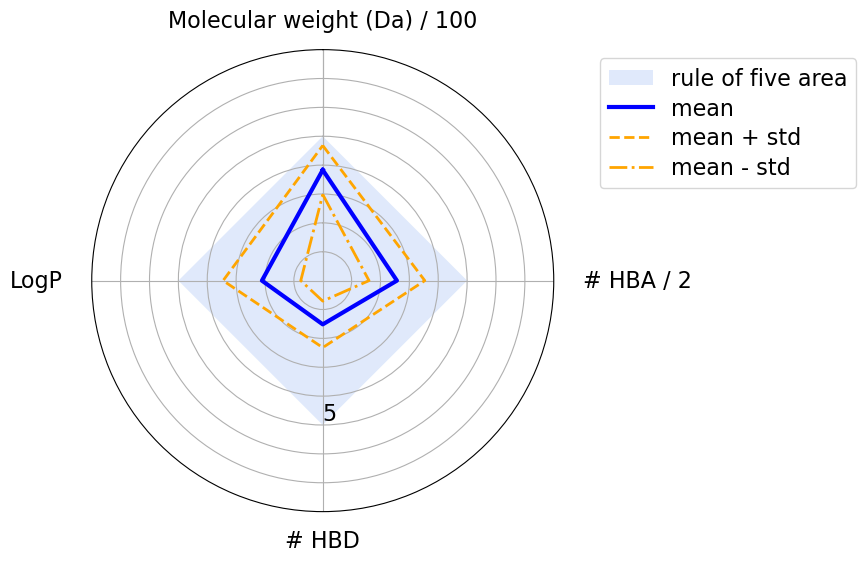

In [43]:
plot_radar(
    molecules_ro5_fulfilled_stats,
    thresholds,
    scaled_threshold,
    properties_labels,
    y_max,
    output_path="radar_plot_ro5_fulfilled.png"
)

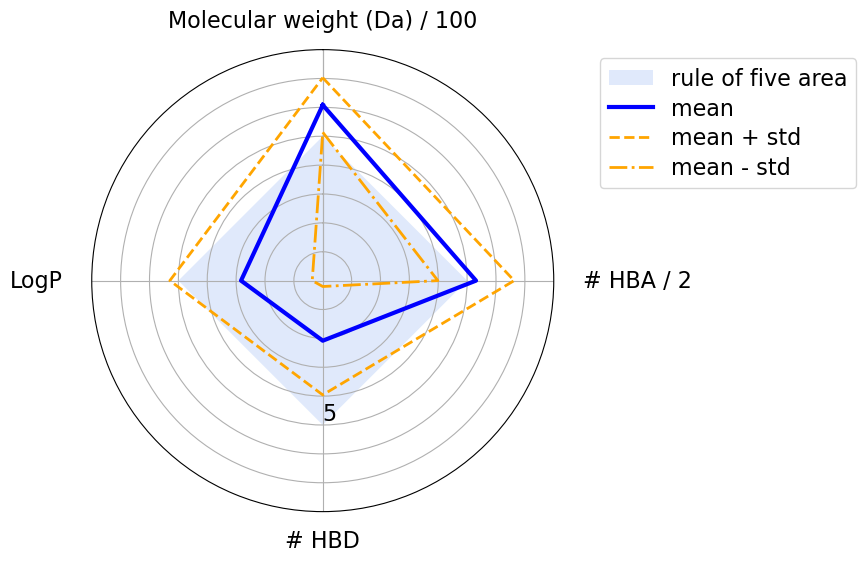

In [44]:
# radar plot for moledules that violated ro5
plot_radar(
    molecules_ro5_violated_stats,
    thresholds,
    scaled_threshold,
    properties_labels,
    y_max,
    output_path="radar_plot_ro5_violated.png"
)

In [45]:
# Load the data from the CSV file
filtered_compounds = pd.read_csv('ro5_properties_filtered.csv')

# Convert SMILES column to molecular structure
PandasTools.AddMoleculeColumnToFrame(filtered_compounds, "canonical_smiles")

# Display the DataFrame
filtered_compounds.head(5)
     

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled,ROMol
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,426.220181,7,1,1.56612,True,<rdkit.Chem.rdchem.Mol object at 0x79f1a53b2730>
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,216.106277,2,1,2.46339,True,<rdkit.Chem.rdchem.Mol object at 0x79f1a53b27a0>
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,316.991222,6,1,2.61660,True,<rdkit.Chem.rdchem.Mol object at 0x79f1a53b2810>
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,276.158626,4,1,-0.57342,True,<rdkit.Chem.rdchem.Mol object at 0x79f1a53b2880>
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,417.191323,9,1,0.37738,True,<rdkit.Chem.rdchem.Mol object at 0x79f1a53b28f0>


# Histogram for each properties of ro5

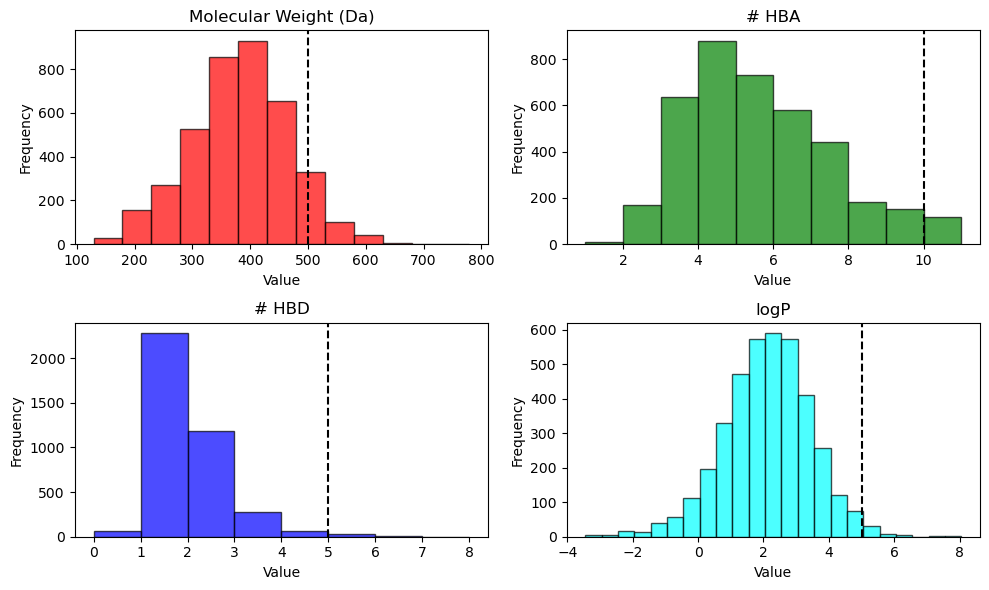

In [46]:
# Define Rule of Five properties and thresholds
ro5_properties1 = {
    "molecular_weight": (500, "Molecular Weight (Da)", 50),
    "n_hba": (10, "# HBA", 1),
    "n_hbd": (5, "# HBD", 1),
    "logp": (5, "logP", 0.5),
}

# Create figure and axes
fig, axes = plt.subplots(figsize=(10, 6), nrows=2, ncols=2)
axes = axes.flatten()  # Flatten to easily loop through subplots
colors = ["red", "green", "blue", "cyan"]

# Create vertical histograms for each property
for index, (key, (threshold, title, bin_size)) in enumerate(ro5_properties1.items()):
    ax = axes[index]
    bins = np.arange(filtered_compounds[key].min(), filtered_compounds[key].max() + bin_size, bin_size)

    ax.hist(filtered_compounds[key], bins=bins, color=colors[index], alpha=0.7, edgecolor="black")
    ax.axvline(x=threshold, color="black", linestyle="dashed", linewidth=1.5, label="Threshold")
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

# Adjust layout
plt.tight_layout()

# ✅ Save the figure before showing
plt.savefig("ro5_histograms_filtered.png", dpi=300, bbox_inches="tight")

plt.show()


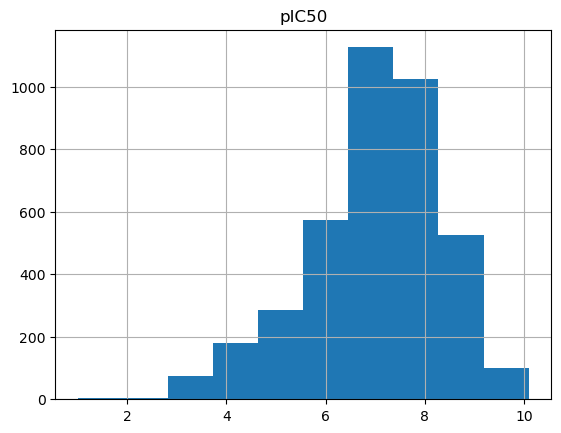

In [47]:
filtered_compounds.hist(column="pIC50")
plt.savefig("pIC50_histogram_Ro5_filtered.png", dpi=300, bbox_inches="tight")
plt.show()
     

# Exploratory Data Analysis

In [48]:
! pip install rdkit==2024.09.6

In [49]:
import pandas as pd
import numpy as np
from rdkit import Chem

In [50]:
df = pd.read_csv('ro5_properties_filtered.csv')
df

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,426.220181,7,1,1.56612,True
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,216.106277,2,1,2.46339,True
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,316.991222,6,1,2.61660,True
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,276.158626,4,1,-0.57342,True
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,417.191323,9,1,0.37738,True
...,...,...,...,...,...,...,...,...,...
3896,CHEMBL3343900,Inactive,5.551294,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,280.022786,5,3,1.67360,True
3897,CHEMBL511367,Inactive,5.850781,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1,287.055014,5,5,2.90890,True
3898,CHEMBL165,Active,9.221849,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,228.078644,3,3,2.97380,True
3899,CHEMBL3675619,Active,8.000000,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,442.222957,7,1,2.21669,True


In [51]:
df1 = df.copy()
df1.rename(columns={'bioactivity_class': 'class'}, inplace=True)
df1

,molecule_chembl_id,class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,426.220181,7,1,1.56612,True
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,216.106277,2,1,2.46339,True
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,316.991222,6,1,2.61660,True
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,276.158626,4,1,-0.57342,True
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,417.191323,9,1,0.37738,True
...,...,...,...,...,...,...,...,...,...
3896,CHEMBL3343900,Inactive,5.551294,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,280.022786,5,3,1.67360,True
3897,CHEMBL511367,Inactive,5.850781,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1,287.055014,5,5,2.90890,True
3898,CHEMBL165,Active,9.221849,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,228.078644,3,3,2.97380,True
3899,CHEMBL3675619,Active,8.000000,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,442.222957,7,1,2.21669,True


# Exploratory Data Analysis (Chemical Space Analysis) via Lipinski descriptor

In [52]:
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

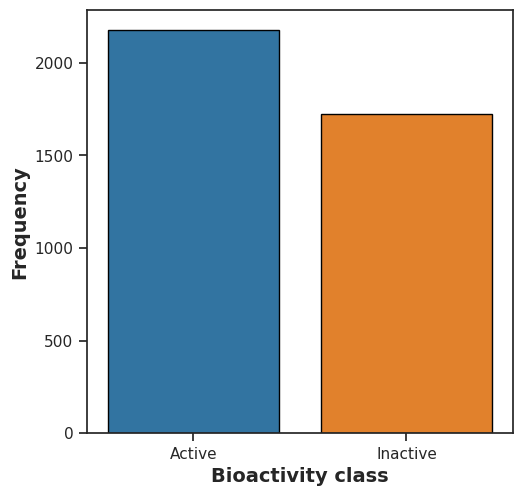

In [53]:
# frequency plot for 2 bioactivity class
plt.figure(figsize=(5.5, 5.5))

sns.countplot(x='class', data=df1, hue='class', edgecolor='black', palette=['#1f77b4', '#ff7f0e'])

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')

plt.savefig('plot_bioactivity_class.png')

# scatter plot of MW vs LogP

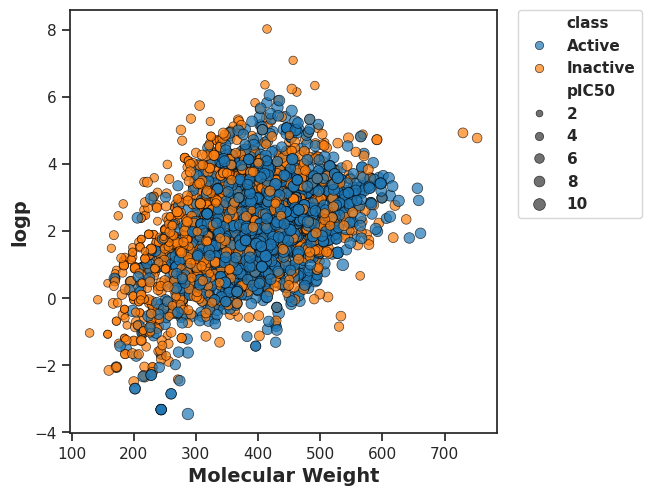

In [54]:
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(x='molecular_weight', y='logp', data=df1, hue='class', size='pIC50', edgecolor='black', alpha=0.7,palette=['#1f77b4', '#ff7f0e'])

plt.xlabel('Molecular Weight', fontsize=14, fontweight='bold')
plt.ylabel('logp', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0, prop={'weight': 'bold'})
plt.savefig('plot_molecular_weight_vs_logp.png', bbox_inches='tight', dpi=300)

# Box Plots

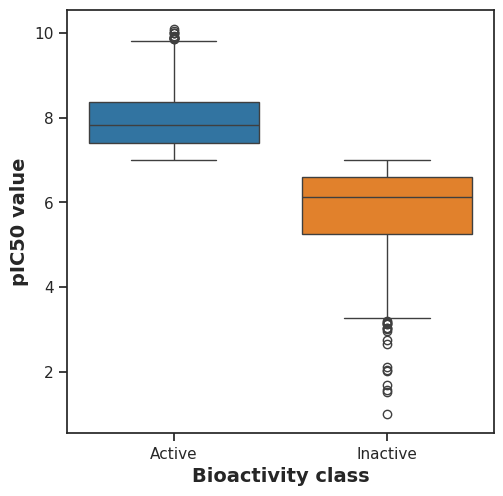

In [55]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'pIC50', hue='class', data = df1, palette=['#1f77b4', '#ff7f0e'])

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')

plt.savefig('box_plot_pic50.png')

In [56]:
def mannwhitney(descriptor, verbose=False):
  # https://machinelearningmastery.com/nonparametric-statistical-significance-tests-in-python/
  from numpy.random import seed
  from numpy.random import randn
  from scipy.stats import mannwhitneyu

# seed the random number generator
  seed(1)

# actives and inactives
  selection = [descriptor, 'class']
  df = df1[selection]
  active = df[df['class'] == 'Active']
  active = active[descriptor]

  selection = [descriptor, 'class']
  df = df1[selection]
  inactive = df[df['class'] == 'Inactive']
  inactive = inactive[descriptor]

# compare samples
  stat, p = mannwhitneyu(active, inactive)
  #print('Statistics=%.3f, p=%.3f' % (stat, p))

# interpret
  alpha = 0.05
  if p > alpha:
    interpretation = 'Same distribution (fail to reject H0)'
  else:
    interpretation = 'Different distribution (reject H0)'

  results = pd.DataFrame({'Descriptor':descriptor,
                          'Statistics':stat,
                          'p':p,
                          'alpha':alpha,
                          'Interpretation':interpretation}, index=[0])
  filename = 'mannwhitneyu_' + descriptor + '.csv'
  results.to_csv(filename)

  return results

In [57]:
mannwhitney('pIC50')

,Descriptor,Statistics,p,alpha,Interpretation
0,pIC50,3753148.0,0.0,0.05,Different distribution (reject H0)


# molecular weight

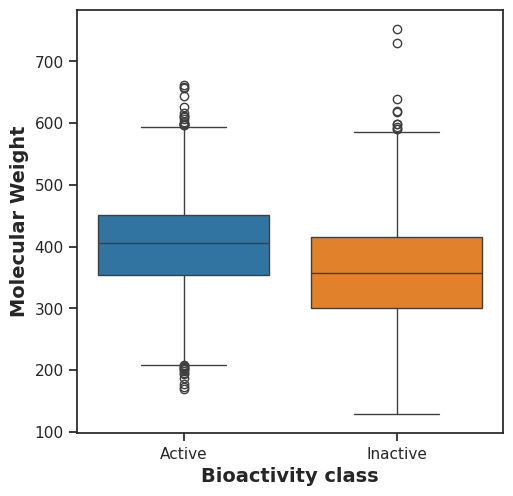

In [58]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'molecular_weight', hue='class', data = df1,palette=['#1f77b4', '#ff7f0e'])

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Molecular Weight', fontsize=14, fontweight='bold')

plt.savefig('plot_MW.png')

In [59]:
mannwhitney('molecular_weight')

,Descriptor,Statistics,p,alpha,Interpretation
0,molecular_weight,2447866.0,4.116418e-60,0.05,Different distribution (reject H0)


# LogP #lipophilicity

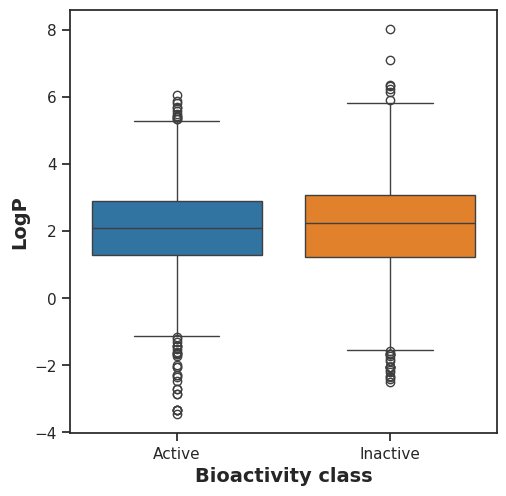

In [60]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'logp',hue='class', data = df1, palette=['#1f77b4', '#ff7f0e'])

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')

plt.savefig('plot_LogP.png')
     

In [61]:
mannwhitney('logp')

,Descriptor,Statistics,p,alpha,Interpretation
0,logp,1805592.5,0.042169,0.05,Different distribution (reject H0)


# Num H Donors

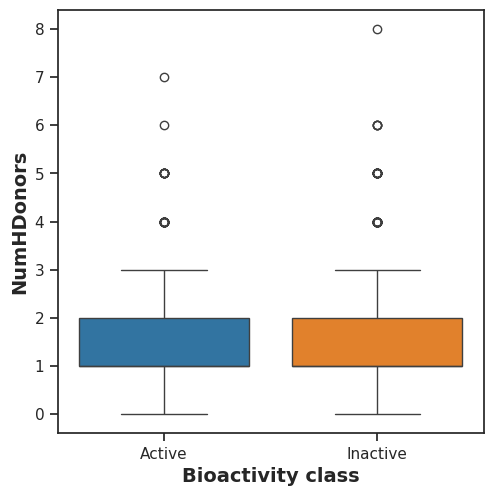

In [62]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'n_hbd', hue='class', data = df1, palette=['#1f77b4', '#ff7f0e'])

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHDonors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHDonors.png')

In [63]:
mannwhitney('n_hbd')

,Descriptor,Statistics,p,alpha,Interpretation
0,n_hbd,1779691.5,0.001599,0.05,Different distribution (reject H0)


# Num H acceptors

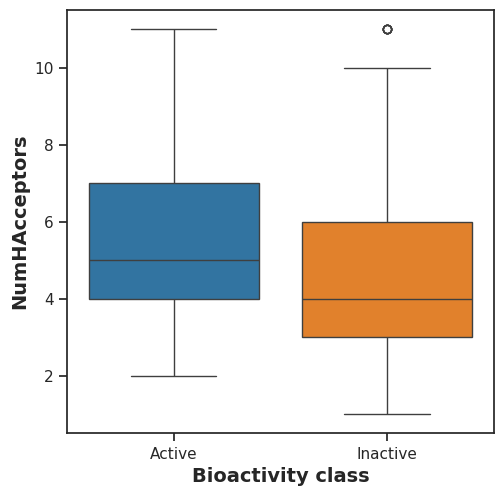

In [64]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'n_hba', hue='class', data = df1, palette=['#1f77b4', '#ff7f0e'])

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHAcceptors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHAcceptors.png')

In [65]:
mannwhitney('n_hba')

,Descriptor,Statistics,p,alpha,Interpretation
0,n_hba,2452117.0,1.183585e-62,0.05,Different distribution (reject H0)


# MACCS rdkit part 1

In [66]:
# Importing Libraries
import pandas as pd
import numpy as np
import warnings

from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem, PandasTools, MACCSkeys
from rdkit.DataStructs import ConvertToNumpyArray

from rdkit import DataStructs
from rdkit.Chem.rdmolops import PatternFingerprint
pd.set_option('display.max_rows', None)

In [67]:
df = pd.read_csv('ro5_properties_filtered.csv')
df.head()

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,426.220181,7,1,1.56612,True
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,216.106277,2,1,2.46339,True
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,316.991222,6,1,2.61660,True
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,276.158626,4,1,-0.57342,True
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,417.191323,9,1,0.37738,True


In [68]:
# Generating molecular objects from smiles
df1 = df[['canonical_smiles']].copy()  # Correct way to keep only the "smiles" column
PandasTools.AddMoleculeColumnToFrame(df1, 'canonical_smiles', 'mol')

In [69]:
df1.head()

,canonical_smiles,mol
0,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c510>
1,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c3c0>
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c660>
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c9e0>
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,<rdkit.Chem.rdchem.Mol object at 0x79f27c2acf20>


# MACCS KEY

In [70]:
MACCSkeys.GenMACCSKeys(df1['mol'][0])

In [71]:
# convert bit vectors into 0 and 1 using Numpy array

In [72]:
maccs = [MACCSkeys.GenMACCSKeys(x) for x in df1['mol']]

maccs_lists = [list(l) for l in maccs]

maccs_name = [f'MACCS_{i}' for i in range(167)]

maccs_df = pd.DataFrame(maccs_lists, index=df1.index, columns=maccs_name)

maccs_df.shape

(3901, 167)

In [73]:
# concat with original dataframe
MACCS = pd.concat([df1, maccs_df], axis=1)
MACCS.head()

,canonical_smiles,mol,MACCS_0,MACCS_1,MACCS_2,MACCS_3,MACCS_4,MACCS_5,MACCS_6,MACCS_7,...,MACCS_157,MACCS_158,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166
0,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c510>,0,0,0,0,0,0,0,0,...,0,1,0,1,1,1,1,1,1,0
1,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c3c0>,0,0,0,0,0,0,0,0,...,0,1,0,1,1,1,1,0,1,0
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c660>,0,0,0,0,0,0,0,0,...,0,1,0,0,1,1,1,1,1,0
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,<rdkit.Chem.rdchem.Mol object at 0x79f27c37c9e0>,0,0,0,0,0,0,0,0,...,0,1,1,1,1,0,0,1,1,0
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,<rdkit.Chem.rdchem.Mol object at 0x79f27c2acf20>,0,0,0,0,0,0,0,0,...,0,1,1,1,1,1,1,1,1,0


In [74]:
# dropping first column to make 166 digits maccs key
MACCS.drop(columns=['MACCS_0'], inplace=True)

In [75]:
# Combine MACCS fingerprints with pIC50 column
MACCS_final = pd.concat([df[['pIC50',	'bioactivity_class']], MACCS.drop(columns=['mol'])], axis=1)

# Save to CSV
MACCS_final.to_csv('maccs_final.csv', index=False)

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from rdkit import DataStructs
from scipy.spatial.distance import pdist, squareform

In [77]:
maccs_df = pd.read_csv("maccs_final.csv")
maccs_df.head(3)

,pIC50,bioactivity_class,canonical_smiles,MACCS_1,MACCS_2,MACCS_3,MACCS_4,MACCS_5,MACCS_6,MACCS_7,...,MACCS_157,MACCS_158,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166
0,9.000000,Active,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,0,0,0,0,0,0,0,...,0,1,0,1,1,1,1,1,1,0
1,4.460297,Inactive,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,0,0,0,0,0,0,0,...,0,1,0,1,1,1,1,0,1,0
2,4.549751,Inactive,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,0,0,0,0,0,0,0,...,0,1,0,0,1,1,1,1,1,0


## PCA Analysis
Extract MACCS fingerprint columns (assuming they are all except SMILES and pIC50)

In [78]:
maccs_features = maccs_df.drop(columns=["canonical_smiles", "pIC50", "bioactivity_class"])

Perform PCA analysis

In [79]:
pca = PCA(n_components=2, svd_solver='full')
pca_result = pca.fit_transform(maccs_features)
maccs_df["PC1"] = pca_result[:, 0]
maccs_df["PC2"] = pca_result[:, 1]

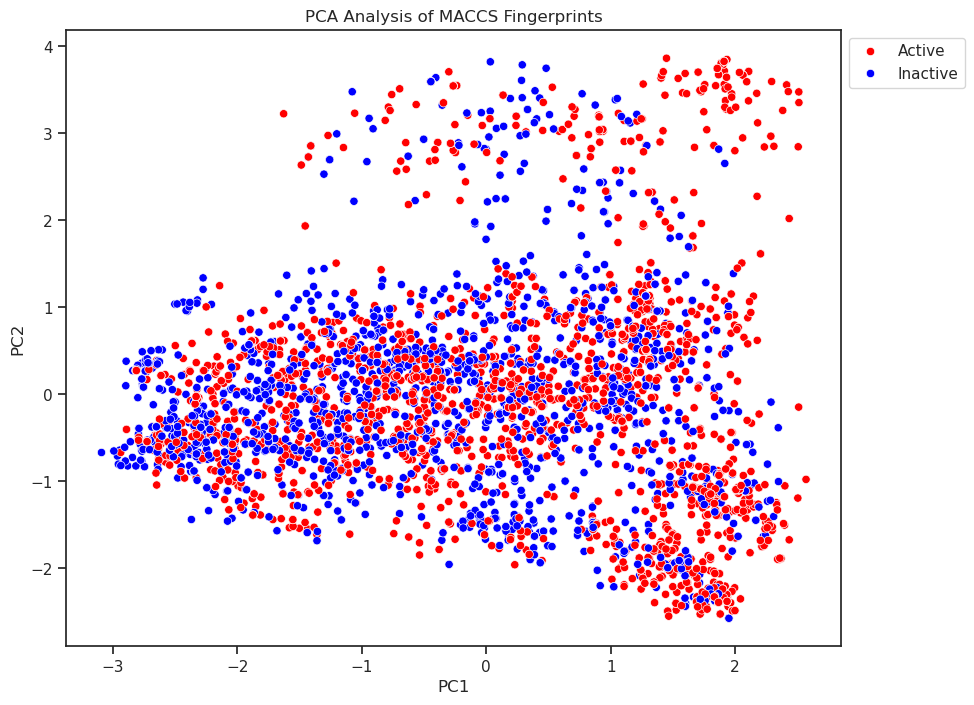

In [80]:
plt.figure(figsize=(10, 8))  # Increased figure size
sns.scatterplot(data=maccs_df, x="PC1", y="PC2", hue="bioactivity_class", palette={"Active": "red", "Inactive": "blue"})
plt.title("PCA Analysis of MACCS Fingerprints")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))  # Move legend outside
plt.savefig("pca_plot.png", bbox_inches='tight')  # Save PCA plot without overlap
plt.show()

In [81]:

!pip install rdkit==2024.09.6

In [82]:
# Importing Libraries
import pandas as pd
import numpy as np
import warnings

from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem, PandasTools,rdFingerprintGenerator
from rdkit import DataStructs

In [83]:
df = pd.read_csv('ro5_properties_filtered.csv')
df.head()

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL5596356,Active,9.000000,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,426.220181,7,1,1.56612,True
1,CHEMBL3310988,Inactive,4.460297,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,216.106277,2,1,2.46339,True
2,CHEMBL4246951,Inactive,4.549751,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,316.991222,6,1,2.61660,True
3,CHEMBL260701,Active,7.221849,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,276.158626,4,1,-0.57342,True
4,CHEMBL3913618,Active,7.795880,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,417.191323,9,1,0.37738,True


In [84]:
df1 = df[['canonical_smiles']].copy()

In [85]:
# Creating molecular object from Smiles
PandasTools.AddMoleculeColumnToFrame(df1,'canonical_smiles','mol')
df1.head()

,canonical_smiles,mol
0,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,<rdkit.Chem.rdchem.Mol object at 0x79f1b6e95930>
1,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a923b0>
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a92490>
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a925e0>
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a91cb0>


# Morgan Fingerprint with radius= 3 and fingerprint size =2048

In [86]:
radius=3
nBits=2048
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nBits)
Morgan = [morgan_gen.GetFingerprint(x) for x in df1['mol']]
morgan_lists = [list(l) for l in Morgan]
morgan_name = [f'morgan_{i}' for i in range(nBits)]
morgan_df = pd.DataFrame(morgan_lists, index=df.index, columns=morgan_name)
morgan_df.shape

(3901, 2048)

In [87]:
MF = pd.concat([df1, pd.DataFrame(morgan_df)], axis=1)
MF.head()

,canonical_smiles,mol,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,...,morgan_2038,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047
0,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,<rdkit.Chem.rdchem.Mol object at 0x79f1b6e95930>,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a923b0>,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a92490>,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a925e0>,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,<rdkit.Chem.rdchem.Mol object at 0x79f1b6a91cb0>,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


### MORGAN FINGER PRINT GENERATION AND SAVE CSV

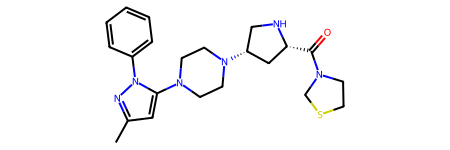

No of ones in the N-Methyl pyrrole MF are:  80
No of zeros in the N-Methyl pyrrole MF are:  1968 

morgan_47      1
morgan_100     1
morgan_105     1
morgan_200     1
morgan_203     1
morgan_219     1
morgan_232     1
morgan_304     1
morgan_340     1
morgan_362     1
morgan_378     1
morgan_389     1
morgan_394     1
morgan_407     1
morgan_470     1
morgan_550     1
morgan_558     1
morgan_585     1
morgan_650     1
morgan_670     1
morgan_675     1
morgan_719     1
morgan_734     1
morgan_789     1
morgan_807     1
morgan_843     1
morgan_875     1
morgan_904     1
morgan_909     1
morgan_922     1
morgan_926     1
morgan_935     1
morgan_1019    1
morgan_1023    1
morgan_1049    1
morgan_1057    1
morgan_1085    1
morgan_1088    1
morgan_1109    1
morgan_1114    1
morgan_1124    1
morgan_1137    1
morgan_1174    1
morgan_1195    1
morgan_1199    1
morgan_1292    1
morgan_1353    1
morgan_1363    1
morgan_1380    1
morgan_1406    1
morgan_1431    1
morgan_1440    1
morgan_1480    1


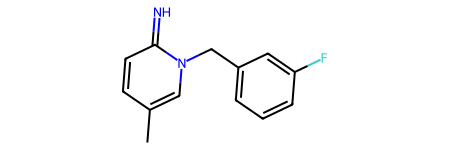

No of ones in the pyrrole MF are:  45
No of zeros in the pyrrole MF are:  2003 

morgan_80      1
morgan_119     1
morgan_130     1
morgan_230     1
morgan_235     1
morgan_279     1
morgan_464     1
morgan_477     1
morgan_590     1
morgan_623     1
morgan_687     1
morgan_699     1
morgan_720     1
morgan_744     1
morgan_828     1
morgan_875     1
morgan_886     1
morgan_899     1
morgan_935     1
morgan_949     1
morgan_1015    1
morgan_1039    1
morgan_1057    1
morgan_1066    1
morgan_1088    1
morgan_1115    1
morgan_1216    1
morgan_1319    1
morgan_1360    1
morgan_1380    1
morgan_1455    1
morgan_1479    1
morgan_1487    1
morgan_1670    1
morgan_1691    1
morgan_1722    1
morgan_1750    1
morgan_1754    1
morgan_1765    1
morgan_1823    1
morgan_1848    1
morgan_1873    1
morgan_1928    1
morgan_1961    1
morgan_2041    1
Name: 1, dtype: object


In [88]:
# Combine pIC50 column from df with MF DataFrame after dropping 'mol' column
MF_final = pd.concat([df[['pIC50', 'bioactivity_class']], MF.drop(columns=['mol'])], axis=1)

# Save to CSV
MF_final.to_csv('morgan_3_2048.csv', index=False)



# print first molecule in the dataset
display(MF.iloc[0,1])
nmpyrrole = MF.iloc[0,2:]

# get the number of ones and zeros in the first molecule
print(f'No of ones in the N-Methyl pyrrole MF are:  {nmpyrrole[nmpyrrole==1].count()}')
print(f'No of zeros in the N-Methyl pyrrole MF are:  {nmpyrrole[nmpyrrole==0].count()} \n')

# grab the column names where bits are 1s
print(nmpyrrole[nmpyrrole==1])

# print second molecule in the dataset
display(MF.iloc[1,1])
pyrrole = MF.iloc[1,2:]

# get the number of ones and zeros in the second molecule
print(f'No of ones in the pyrrole MF are:  {nmpyrrole[pyrrole==1].count()}')
print(f'No of zeros in the pyrrole MF are:  {nmpyrrole[pyrrole==0].count()} \n')

# get the column names where bits are 1s
print(pyrrole[pyrrole==1])

Compute Tanimoto similarity matrix

In [89]:
morgan_df = pd.read_csv("morgan_3_2048.csv")

In [90]:
morgan_features = morgan_df.drop(columns=["canonical_smiles", "pIC50", "bioactivity_class"])

In [91]:
def tanimoto_similarity(fp1, fp2):
    return DataStructs.TanimotoSimilarity(fp1, fp2)

In [92]:
morgan_fps = [DataStructs.CreateFromBitString("".join(map(str, row))) for row in morgan_features.values]

Compute similarity matrix

In [93]:
tanimoto_matrix = np.array([[tanimoto_similarity(fp1, fp2) for fp2 in morgan_fps] for fp1 in morgan_fps])

In [94]:
np.savetxt("tanimoto_matrix.csv", tanimoto_matrix, delimiter=",", fmt="%.4f", header=",".join(map(str, range(len(morgan_fps)))), comments="")

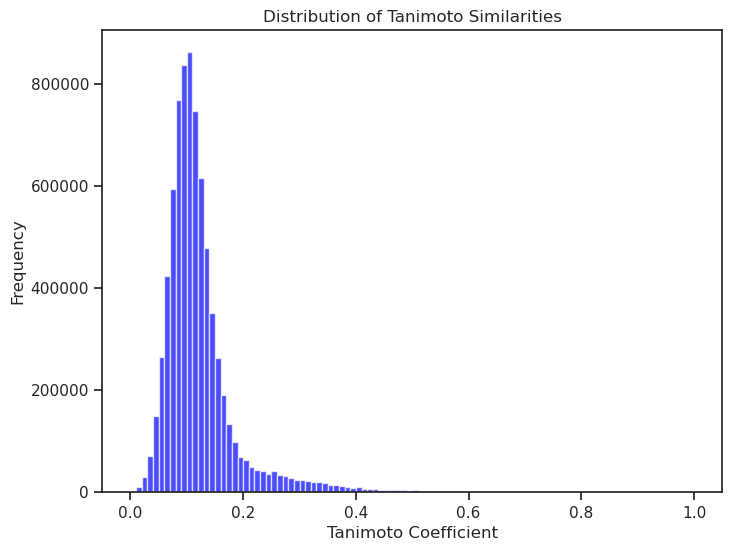

In [95]:
tanimoto_values = tanimoto_matrix[np.triu_indices_from(tanimoto_matrix, k=1)]  # Exclude diagonal
plt.figure(figsize=(8, 6))
plt.hist(tanimoto_values, bins=100, color="blue", alpha=0.7)
plt.xlabel("Tanimoto Coefficient")
plt.ylabel("Frequency")
plt.title("Distribution of Tanimoto Similarities")
plt.savefig("tanimoto_histogram.png")  # Save histogram
plt.show()

## Creating T-SNE Plot

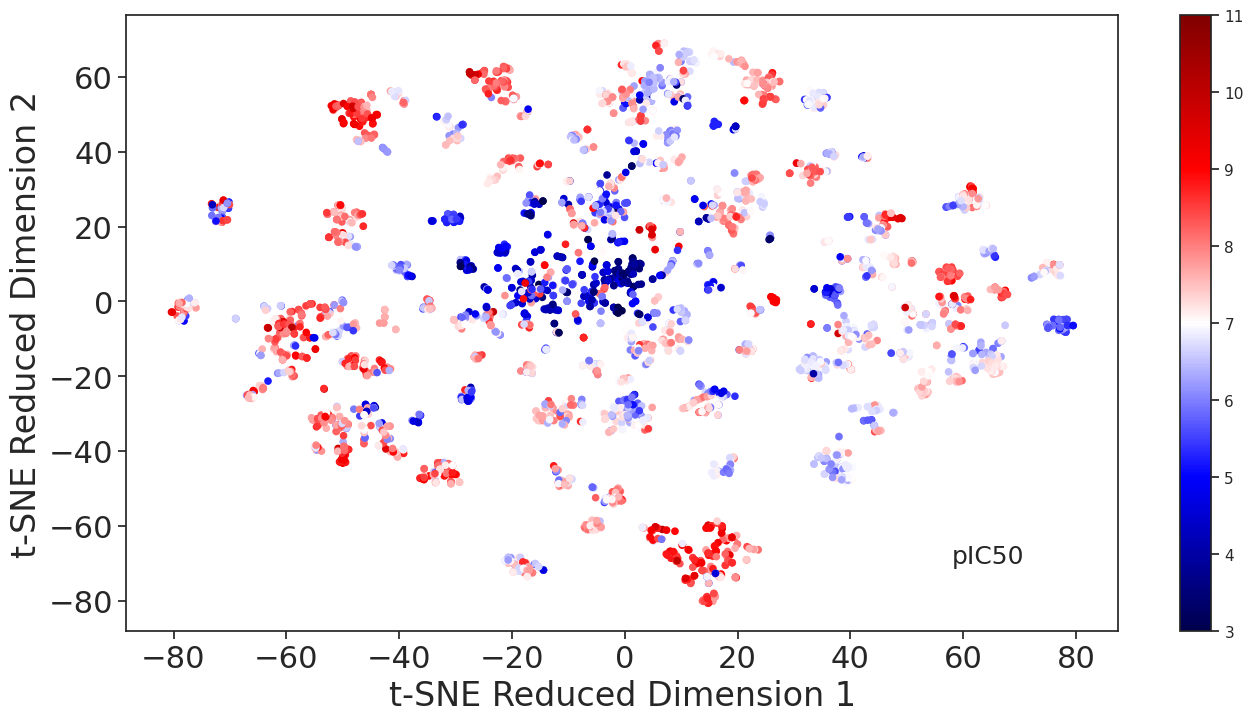

In [96]:
np.random.seed(57)

x_values = morgan_df.drop(columns=["canonical_smiles", "pIC50", "bioactivity_class"])
y_values = morgan_df["pIC50"]

tsne_descriptors = TSNE(n_components=2, random_state=57)
x_tsne = tsne_descriptors.fit_transform(x_values)

# Draw tsne
cm = plt.get_cmap('seismic')
plt.figure(figsize=(16, 8))
plt.xticks(size=22)
plt.yticks(size=22)
plt.xlabel('t-SNE Reduced Dimension 1', size=24)
plt.ylabel('t-SNE Reduced Dimension 2', size=24)
plt.scatter(x_tsne[:, 0], x_tsne[:, 1], c=y_values, vmin=3, vmax=11, s=20, cmap=cm)
plt.colorbar()
plt.text(58, -70, "pIC50", size=18)
plt.savefig("TSNE.png", bbox_inches='tight', pad_inches=0)
plt.show()